# Lab 06 — Evaluation: From Predictions to Defensible Conclusions
### Measure what changed from Base → SFT → DPO → PPO → GRPO

**Language:** English · **Format:** guided lecture + executable practical + independent exercises  
**Suggested time:** three sessions of 90 minutes, plus optional GSM8K inference  
**Prerequisites:** Labs 02–05; conditional probabilities, token cross-entropy, Python and PyTorch

A lower training loss is useful evidence. It is not yet evidence that an assistant solves unseen questions. In this lab, you will turn that distinction into a reproducible evaluation pipeline.

By the end, you should be able to:
1. Specify a task, prompt, decoding rule, scoring rule, and population before measuring performance.
2. Derive accuracy, conditional negative log-likelihood, perplexity, and uncertainty estimates.
3. Load real saved policies without retraining or embedding weights in a notebook.
4. Generate completions in equal-length batches, respect context limits, and restore example order.
5. Reproduce the repository's tolerant numerical scoring and expose its failure cases.
6. Compare all five policy stages, audit individual predictions, and save reproducible evidence.
7. Run the repository's actual GSM8K evaluation on compatible checkpoints.

**Two clearly separated experiments**

| Track | Inputs and checkpoints | What it establishes |
|---|---|---|
| A: executable CPU practical | Lab 03 ASCII base + Lab 05 SFT/DPO/PPO/GRPO | The evaluation pipeline works; small-model behavior on compact arithmetic |
| B: repository benchmark | Repository checkpoints + r50k_base chat template + GSM8K | The actual Step 6 headline metric |

Track A is not GSM8K and must never be presented as a GSM8K score. Track B is implemented below, but requires your repository environment, dataset access, and trained repository checkpoints. Its execution status is printed explicitly.

This is independently authored teaching material inspired by [Stanford CS336, Spring 2025, Lecture 12: Evaluation](https://github.com/stanford-cs336/spring2025-lectures/blob/main/lecture_12.py). We adopt its emphasis on specifying the evaluation question, inspecting predictions, and distinguishing a model score from a claim about a training method. The uncertainty calculations and exercises here are additional lab material; this is not an official Stanford assignment.


## 1. Reading map: every component of repository Step 6

Sources inspected on **14 November 2026**. Git blob IDs identify the inspected file contents; they are not repository commit IDs. Recheck them if upstream changes.

| Step 6 responsibility | Source | What this lab covers |
|---|---|---|
| Headline stage comparison and post-SFT behavior | [README, Step 6](https://github.com/FareedKhan-dev/train-llm-from-scratch#step-6-evaluation) | Identical evaluation conditions; numeric accuracy versus formatting |
| CLI, samples, append, table | [eval_post_training.py](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/scripts/eval_post_training.py) | Actual commands, defaults, and durable per-example evidence |
| Dataset, prompts, length buckets, scoring | [evaluation.py](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/src/post_training/evaluation.py) | GSM8K selection, context budget, order restoration |
| Checkpoint reconstruction | [inference.py](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/src/post_training/inference.py) | Use the repository loader for its models; strict Lab checkpoint loading |
| Role markers and EOT | [chat_template.py](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/src/post_training/chat_template.py) | Distinguish Lab ASCII from repository BPE |
| Autoregressive rollout | [rollout.py](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/src/post_training/rollout.py) | Stop per row; no context rollover in this evaluation |
| Numerical extraction | [rewards/parsing.py](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/src/post_training/rewards/parsing.py) | Tags → hash marker → last number |
| Numerical tolerance | [rewards/verifiers.py](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/src/post_training/rewards/verifiers.py) | Absolute tolerance; accuracy is not shaped reward |

Inspected blobs: evaluation `478f8c6b5b2b24b66cfada6b3a4d4cfd2c62e51e`; parsing `fa8d969b4c9cdafaa4c287760e96584e5e912e88`; verifiers `c78b4744e4ee6c98603353433ce34bba7add1b1b`; inference `1ba2b77aec59a1858992d72644c809d456e5daf2`; CLI `7af68c195ac01e125285bfd41b006f53af3251d8`.

**Important source detail:** the README describes answer-tag scoring, but the implementation also accepts a `####` answer and then falls back to the last number. We reproduce the implementation and report format separately.


## 2. Start with the question, not the leaderboard

Our question is: **under one frozen input-and-decoding protocol, which saved policy answers these questions correctly?**

Let $D=\{(q_i,a_i)\}_{i=1}^N$ be the evaluation set, $T$ a prompt template, $G$ the decoding procedure, and $S$ a scoring function. The measured system is

$$\hat a_i=G(\pi_\theta,T(q_i)),\qquad z_i=S(\hat a_i,a_i),\qquad \widehat A=\frac1N\sum_{i=1}^{N}z_i.$$

The score depends on all of $D,T,G,S,\theta$, not just the weights. A longer generation budget, a different parser, or a different chat template changes the experiment.

**Freeze this contract before running:** checkpoint identity, dataset split and example IDs, tokenizer, prompt template, decoding parameters, context limit, stop token, scorer version, and denominator policy. Never give the gold answer to the generator. Never score the prompt concatenated with the response: the question itself may contain the gold number.

| Keep fixed across stages | Why |
|---|---|
| Same questions in the same order | Different difficulty mixes can reverse rankings |
| Same template, token budget, stop rule | Extra reasoning tokens change available computation |
| Same scorer and tolerance | Parsing changes can look like model improvements |
| Same treatment of failed/empty generations | Dropping failures inflates the score |
| Same hardware for timing | Latency comparisons otherwise have a confound |

A base policy may be disadvantaged by a chat template it never learned. The repository deliberately evaluates all stages through the same chat interface. That measures progress under that interface. A separate raw-prompt base experiment is useful, but it must have a different protocol label.

**Predict before coding:** if a policy produces the right number without tags, should it receive numerical credit? Under the repository scorer: yes. Does that prove instruction-format compliance? No.


## 3. Setup and checkpoint contract

Install `torch`, `numpy`, and `matplotlib` in your notebook environment. Track A needs the real files produced by Labs 03 and 05. No checkpoint is embedded and no training is performed.

Set `LAB05_DIR` to one specific completed Lab 05 run if you have several. With exactly one complete run it can be discovered automatically; otherwise this cell asks you to select explicitly. The base checkpoint is resolved from that run's recorded `source_checkpoint`, avoiding an accidental comparison with a different pretraining run.

Only load checkpoint files you created or trust. This lab uses `weights_only=True`, validates the tokenizer and dimensions, and loads policy weights strictly. `reward.pt` is a scalar reward model, not a sixth policy stage.


In [1]:
import json, math, re, hashlib, tempfile, time, csv, sys, subprocess
from pathlib import Path
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F

torch.manual_seed(42)
torch.set_num_threads(1)
DEVICE = "cpu"
LAB05_DIR = Path("lab05_runs/run_46tulole")  # Change to YOUR completed Lab 05 run.
BASE_PATH_OVERRIDE = None  # Set if you moved the Lab 03 checkpoint.
STAGES = ["base", "sft", "dpo", "ppo", "grpo"]
if LAB05_DIR is None:
    complete = [p for p in Path("lab05_runs").glob("*")
                if all((p/f"{s}.pt").is_file() for s in STAGES[1:])]
    if len(complete) != 1:
        raise ValueError(f"Set LAB05_DIR explicitly. Complete runs: {complete}")
    LAB05_DIR = complete[0]
LAB05_DIR = Path(LAB05_DIR)
for stage in STAGES[1:]:
    if not (LAB05_DIR/f"{stage}.pt").is_file():
        raise FileNotFoundError(f"Missing {stage}.pt in {LAB05_DIR}; run Lab 05 or fix LAB05_DIR.")
sft_checkpoint = torch.load(LAB05_DIR/"sft.pt", map_location="cpu", weights_only=True)
BASE_PATH = Path(BASE_PATH_OVERRIDE or sft_checkpoint["source_checkpoint"])
CHECKPOINTS = {"base":BASE_PATH, **{s:LAB05_DIR/f"{s}.pt" for s in STAGES[1:]}}
EXPECTED_TOKENIZER = {"kind":"ascii-character", "vocab_size":129, "eot_id":128}
EOT = 128

def sha256_file(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda: f.read(1024*1024), b""):
            h.update(chunk)
    return h.hexdigest()

def canonical_hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False).encode()).hexdigest()

Path("lab06_runs").mkdir(exist_ok=True)
RUN_DIR = Path(tempfile.mkdtemp(prefix="evaluation_", dir="lab06_runs"))
print("Policies:", {s:str(p) for s,p in CHECKPOINTS.items()})
print("PyTorch:", torch.__version__, "| device:", DEVICE, "| outputs:", RUN_DIR)


Policies: {'base': 'lab03_runs/run_pvg4r57e/final.pt', 'sft': 'lab05_runs/run_46tulole/sft.pt', 'dpo': 'lab05_runs/run_46tulole/dpo.pt', 'ppo': 'lab05_runs/run_46tulole/ppo.pt', 'grpo': 'lab05_runs/run_46tulole/grpo.pt'}
PyTorch: 2.15.0+cpu | device: cpu | outputs: /workspace/scratch/d20f4a09d498/lab06_runs/evaluation_uga55ouu


### 3.1 Reuse the architecture, not a freshly initialized model

The next cell contains the same small model definitions used in Lab 03. It only reconstructs the module structure so PyTorch can load its saved parameters. Strict loading catches mismatched keys or tensor shapes. A successful forward pass with randomly initialized weights would not validate checkpoint continuity.


In [2]:
class MLP(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.hidden = nn.Linear(width, 4 * width)
        self.proj = nn.Linear(4 * width, width)

    def forward(self, x):
        return self.proj(F.relu(self.hidden(x)))

def causal_attention(q, k, v):
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.shape[-1])
    length = q.shape[-2]
    allowed = torch.ones(length, length, dtype=torch.bool, device=q.device).tril()
    weights = scores.masked_fill(~allowed, float("-inf")).softmax(dim=-1)
    return weights @ v, weights

class Head(nn.Module):
    def __init__(self, width, head_width):
        super().__init__()
        self.query = nn.Linear(width, head_width, bias=False)
        self.key = nn.Linear(width, head_width, bias=False)
        self.value = nn.Linear(width, head_width, bias=False)

    def forward(self, x):
        output, _ = causal_attention(self.query(x), self.key(x), self.value(x))
        return output

class MultiHeadAttention(nn.Module):
    def __init__(self, width, heads):
        super().__init__()
        if width % heads:
            raise ValueError("Embedding width must be divisible by head count.")
        self.heads = nn.ModuleList([Head(width, width // heads) for _ in range(heads)])
        self.proj = nn.Linear(width, width)

    def forward(self, x):
        return self.proj(torch.cat([head(x) for head in self.heads], dim=-1))

class Block(nn.Module):
    def __init__(self, width, heads):
        super().__init__()
        self.ln1 = nn.LayerNorm(width)
        self.attn = MultiHeadAttention(width, heads)
        self.ln2 = nn.LayerNorm(width)
        self.mlp = MLP(width)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        return x + self.mlp(self.ln2(x))

class Transformer(nn.Module):
    def __init__(self, vocab_size, width, heads, context_length, layers):
        super().__init__()
        self.context_length = context_length
        self.token_embed = nn.Embedding(vocab_size, width)
        self.position_embed = nn.Embedding(context_length, width)
        self.blocks = nn.ModuleList([Block(width, heads) for _ in range(layers)])
        self.norm = nn.LayerNorm(width)
        self.lm_head = nn.Linear(width, vocab_size)

    def forward_hidden(self, ids):
        length = ids.shape[1]
        if not 1 <= length <= self.context_length:
            raise ValueError("Sequence length is outside the supported context.")
        positions = torch.arange(length, device=ids.device)
        hidden = self.token_embed(ids) + self.position_embed(positions)
        for block in self.blocks:
            hidden = block(hidden)
        return self.norm(hidden)

    def forward(self, ids, targets=None):
        logits = self.lm_head(self.forward_hidden(ids))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), targets.reshape(-1).long())
        return logits, loss


In [3]:
def load_lab_policy(path, expected_stage):
    ckpt = torch.load(path, map_location="cpu", weights_only=True)
    if ckpt.get("tokenizer") != EXPECTED_TOKENIZER:
        raise ValueError("Tokenizer mismatch: this loader is only for the Lab ASCII model.")
    cfg = ckpt["config"]
    if expected_stage != "base" and ckpt.get("stage") != expected_stage:
        raise ValueError("Checkpoint stage does not match its evaluation label.")
    model = Transformer(129, cfg["width"], cfg["heads"], cfg["context_length"], cfg["layers"])
    model.load_state_dict(ckpt["model_state"], strict=True)
    model.to(DEVICE).eval().requires_grad_(False)
    return model, ckpt

models, checkpoint_metadata = {}, {}
for stage,path in CHECKPOINTS.items():
    models[stage], checkpoint_metadata[stage] = load_lab_policy(path, stage)
base_cfg = checkpoint_metadata["base"]["config"]
for stage in STAGES[1:]:
    meta = checkpoint_metadata[stage]
    for key in ("width", "heads", "layers", "context_length"):
        assert meta["config"][key] == base_cfg[key], (stage,key)
    assert meta.get("chat_template") == "U:{a}+{b}\nA:"
    source = Path(meta["source_checkpoint"])
    if source.exists():
        assert sha256_file(source) == sha256_file(BASE_PATH), "Mixed base lineage"
print("Strictly loaded", len(models), "policies; context =", base_cfg["context_length"])
print("Parameters per policy:", sum(p.numel() for p in models["base"].parameters()))


Strictly loaded 5 policies; context = 24
Parameters per policy: 34433


## 4. Build the dataset before seeing the predictions

Lab 05 trained on 12 addition pairs with operands in $\{0,1,2,3\}$ and repeatedly inspected four validation pairs. Those four remain **validation**, not a fresh test set.

We report three slices separately:
- **train_seen:** a diagnostic of memorization, never a generalization claim.
- **validation_reused:** the same four pairs; useful continuity, but already exposed during development.
- **ood_probe:** new operand combinations involving 4 or 5, with one-digit sums. This is a deliberately small distribution-shift probe, not a representative statistical sample of arithmetic or GSM8K.

The OOD set is frozen before this run. Once its results influence training or prompt design, treat it as development data and collect a new test set. Disjoint exact strings do not prove absence of semantic overlap; addition is commutative and near-duplicate questions may share structure.


In [4]:
validation_pairs = {(0,1),(1,3),(2,2),(3,0)}
train_pairs = [(a,b) for a in range(4) for b in range(4) if (a,b) not in validation_pairs]
ood_pairs = [(4,b) for b in range(4)] + [(a,5) for a in range(4)]

def make_example(a,b,split):
    return {"id":f"{split}:{a}+{b}", "split":split,
            "prompt":f"U:{a}+{b}\nA:", "gold":a+b, "a":a, "b":b}

examples = ([make_example(a,b,"train_seen") for a,b in train_pairs]
    + [make_example(a,b,"validation_reused") for a,b in sorted(validation_pairs)]
    + [make_example(a,b,"ood_probe") for a,b in ood_pairs])
assert len({e["id"] for e in examples}) == len(examples)
assert len({e["prompt"] for e in examples}) == len(examples)
assert set(train_pairs).isdisjoint(validation_pairs)
assert set(ood_pairs).isdisjoint(train_pairs + list(validation_pairs))
assert all(0 <= e["gold"] <= 9 for e in examples)
DATASET_HASH = canonical_hash(examples)
print("Frozen dataset:", DATASET_HASH)
for split in ("train_seen", "validation_reused", "ood_probe"):
    print(split, sum(e["split"] == split for e in examples))
print("Prompt only:", repr(examples[0]["prompt"]))


Frozen dataset: 94f3dd3ae41514916c8a4c35ab45c823b8ff13ae81491ffcdecb4c98bd7f0d55
train_seen 12
validation_reused 4
ood_probe 8
Prompt only: 'U:0+0\nA:'


## 5. Mathematics of the headline metric

For a generated response $r_i$, let $P(r_i)$ extract a number and $g_i$ be the parsed gold number. The repository uses

$$z_i=\mathbf1\{P(r_i)\ne\varnothing,\ g_i\ne\varnothing,\ |P(r_i)-g_i|\le10^{-4}\},\qquad \widehat A=\frac{\sum_i z_i}{N}.$$

It calls `math.isclose` with zero relative tolerance and absolute tolerance $10^{-4}$. Thus a tolerance of $10^{-4}$ does not grow with answer magnitude. Missing parsed answers score zero. Empty generated responses stay in the denominator.

The training verifier can return correctness plus a **0.2 formatting bonus**, clipped at 1.2. Evaluation accuracy is only the boolean correctness component. A reward of 0.2 is not 20% mathematical accuracy.

Numerical accuracy also does not verify the correctness of intermediate reasoning. A response may guess the right final number after an invalid explanation. For reasoning quality you need separate checks or an audited rubric.

### 5.1 A scorer is executable policy

The following compact implementation mirrors the inspected repository's extraction order:
1. First matched `<answer>...</answer>` block containing a number.
2. First `####` numeric marker, if the first block did not yield a number.
3. Last number anywhere in the response.

The gold parser prefers `####`, otherwise takes the first number. The regex handles signs, dollar signs, commas and decimals; it does **not** implement fractions or scientific notation. Do not silently improve the parser while claiming exact reproduction.


In [5]:
NUMBER_RE = re.compile(r"-?\$?\d[\d,]*(?:\.\d+)?")
ANSWER_RE = re.compile(r"<answer>(.*?)</answer>", re.DOTALL)
HASH_RE = re.compile(r"####\s*(-?\$?\d[\d,]*(?:\.\d+)?)")

def parse_number(text):
    if text is None:
        return None
    match = NUMBER_RE.search(text)
    return float(match.group().replace(",", "").replace("$", "")) if match else None

def extract_answer(text):
    match = ANSWER_RE.search(text)
    if match:
        value = parse_number(match.group(1))
        if value is not None:
            return value
    match = HASH_RE.search(text)
    if match:
        return parse_number(match.group(1))
    numbers = NUMBER_RE.findall(text)
    return parse_number(numbers[-1]) if numbers else None

def gsm8k_gold_answer(text):
    match = HASH_RE.search(text)
    return parse_number(match.group(1)) if match else parse_number(text)

def repo_correct(response, gold):
    prediction = extract_answer(response)
    return prediction is not None and gold is not None and math.isclose(
        prediction, gold, rel_tol=0.0, abs_tol=1e-4)

def one_answer_block(response):
    return len(ANSWER_RE.findall(response)) == 1

scorer_cases = [
    ("<answer>42</answer>",42,True),
    ("<answer>$1,200.50</answer>",1200.5,True),
    ("<answer>-3</answer>",-3,True),
    ("We get 7. #### 42",42,True),
    ("There were 7, now 42",42,True),
    ("<answer>7</answer> #### 42",42,False),
    ("<answer></answer> fallback 42",42,True),
    ("<answer>7</answer><answer>42</answer>",42,False),
    ("no numeric answer",42,False),
    ("",42,False),
    ("<answer>1.00005</answer>",1,True),
    ("<answer>1.0002</answer>",1,False),
    ("<answer>1/2</answer>",0.5,False),
    ("<answer>1e3</answer>",1000,False),
]
for response,gold,expected in scorer_cases:
    assert repo_correct(response,gold) == expected, response
assert one_answer_block("<answer></answer>")  # Structural check does not require a number.
assert gsm8k_gold_answer("A calculation uses 7. #### 42") == 42
assert repo_correct("<answer>1/2</answer>",1)  # Deliberate parser limitation: parses 1.
print("Passed",len(scorer_cases),"scoring cases and structural/gold-parser checks.")
print("Counterexample: '1/2' inside answer tags is extracted as",extract_answer("<answer>1/2</answer>"))


Passed 14 scoring cases and structural/gold-parser checks.
Counterexample: '1/2' inside answer tags is extracted as 1.0


### 5.2 Format, parseability, and correctness are different axes

For Track A, the desired completion is a single digit followed by EOT, because that is what Lab 05 trained. We therefore record strict digit-only correctness as well as repository-style numerical correctness. XML-tag compliance would be meaningless for this tiny chat template.

For Track B, report answer-block rate separately from numerical accuracy. The repository's `has_well_formed_answer` checks whether exactly one matching block exists; even an empty block passes. A stronger format validator is a useful extension, but label it separately.

**Mini-exercise:** construct one response with correct formatting and wrong arithmetic, and another with correct arithmetic and no formatting. Why would a single reward scalar hide this distinction?


## 6. Generation: equal-length buckets and a finite budget

At each step, greedy decoding chooses

$$x_{t+1}=\arg\max_v p_\theta(v\mid x_{\le t}).$$

Track A uses `argmax`, with deterministic first-index tie breaking. The repository implements its greedy mode through temperature 1, top-k 1 and no top-p filtering, then samples from the filtered distribution. With a unique maximum these agree. Exact ties can depend on the filtering implementation; do not promise bit-identical results across implementations or hardware.

If a prompt has $L$ tokens, the context capacity is $C$, and the requested completion length is $M$, the evaluation budget is

$$B=\max(0,\min(M,C-L)).$$

The Step 6 evaluator does not roll the context window forward indefinitely. It returns an empty response when there is no room. We preserve that denominator policy and additionally record the reason. Invalid or empty input prompts are rejected in our Track A harness.

Why bucket? These models have no padding-aware attention mask. Left-padding unequal prompts would make the extra tokens visible and alter positions. Group equal token lengths, generate independently within each group, stop each row at its first EOT, then restore original order. Padding after a row finishes is bookkeeping and must not enter its decoded response.


In [6]:
def encode_ascii(text):
    ids = [ord(c) for c in text]
    if not ids or any(t >= EOT for t in ids):
        raise ValueError("Expected a nonempty ASCII prompt.")
    return ids

def decode_ascii(ids):
    return "".join(chr(t) for t in ids if 0 <= t < EOT)

@torch.inference_mode()
def generate_bucketed(model, prompts, max_new_tokens=8, micro_batch=8):
    if max_new_tokens < 0 or micro_batch < 1:
        raise ValueError("Invalid token budget or batch size.")
    if any(not p for p in prompts):
        raise ValueError("Empty token prompt.")
    results = [None] * len(prompts)
    groups = defaultdict(list)
    for i,prompt_ids in enumerate(prompts):
        groups[len(prompt_ids)].append(i)
    was_training = model.training
    model.eval()
    try:
        for length,indices in sorted(groups.items()):
            budget = max(0,min(max_new_tokens, model.context_length-length))
            for start in range(0,len(indices),micro_batch):
                batch_indices = indices[start:start+micro_batch]
                if budget == 0:
                    for i in batch_indices:
                        results[i] = {"response":"", "token_ids":[], "generated_tokens":0,
                                      "finish_reason":"no_budget", "budget":0}
                    continue
                sequence = torch.tensor([prompts[i] for i in batch_indices],device=DEVICE)
                done = torch.zeros(len(batch_indices),dtype=torch.bool,device=DEVICE)
                generated = [[] for _ in batch_indices]
                for _ in range(budget):
                    logits = model(sequence)[0][:,-1,:]
                    if not torch.isfinite(logits).all():
                        raise ValueError("Non-finite logits: abort, do not drop examples.")
                    next_ids = logits.argmax(-1)
                    next_ids = torch.where(done, EOT, next_ids)
                    for row,token in enumerate(next_ids.tolist()):
                        if not done[row]:
                            generated[row].append(token)
                    done |= next_ids.eq(EOT)
                    sequence = torch.cat([sequence,next_ids[:,None]],dim=1)
                    if done.all():
                        break
                for row,i in enumerate(batch_indices):
                    tokens = generated[row]
                    stopped = bool(tokens and tokens[-1] == EOT)
                    visible = tokens[:-1] if stopped else tokens
                    results[i] = {"response":decode_ascii(visible), "token_ids":tokens,
                                  "generated_tokens":len(tokens), "budget":budget,
                                  "finish_reason":"eot" if stopped else "length"}
    finally:
        model.train(was_training)
    assert all(row is not None for row in results)
    return results


### 6.1 Test the evaluator before trusting any model score

A deliberately scripted model below is only a unit-test fixture. It tests bucketing order, per-row stopping, EOT removal, microbatch equivalence, and a prompt with zero remaining capacity. It contributes no rows to the real model comparison.


In [7]:
class ScriptedPolicy(nn.Module):
    context_length = 8
    def forward(self, ids):
        logits = torch.full((*ids.shape,129),-1000.0,device=ids.device)
        for row in range(len(ids)):
            last = int(ids[row,-1])
            token = EOT if last in (ord("1"),ord("2"),EOT) else (ord("1") if last == ord("a") else ord("2"))
            logits[row,-1,token] = 1000
        return logits,None

fixture = ScriptedPolicy().train()
test_prompts = [[ord("b")]*3,[ord("a")],[ord("a")]*8,[ord("b")]]
fixture_result = generate_bucketed(fixture,test_prompts,max_new_tokens=4)
assert [r["response"] for r in fixture_result] == ["2","1","","2"]
assert fixture_result[2]["finish_reason"] == "no_budget"
assert fixture_result[0]["token_ids"] == [ord("2"),EOT]
assert fixture.training  # Caller state restored.
assert fixture_result == generate_bucketed(fixture,test_prompts,4,micro_batch=1)
assert generate_bucketed(fixture,[],4) == []
print("Generation contract tests passed. Scripted fixtures are excluded from results.")


Generation contract tests passed. Scripted fixtures are excluded from results.


## 7. Run the real five-stage comparison

We keep unrestricted greedy decoding: the full vocabulary is available at every step. Masking the vocabulary down to digits would give the model a different task. This matters because Lab 05 used constrained actions in parts of its PPO/GRPO teaching exercises; those training simplifications must remain visible when interpreting generalization.

Our record contains the raw completion, parsed number, strict correctness, numerical correctness, stop reason, token IDs, and example identity. Timing is exploratory CPU wall time, not a rigorously warmed-up latency benchmark.

**Before running, write a prediction:** which stage will improve the training slice? Which will improve the reused validation slice? It is valid for post-training to improve memorization while leaving generalization unchanged or worse.


In [8]:
MAX_NEW_TOKENS = 8
MICRO_BATCH = 8
SCORER_VERSION = "repo-numeric-abs1e-4+lab-digit-v1"
encoded_prompts = [encode_ascii(e["prompt"]) for e in examples]
records, timings = [], {}
for stage in STAGES:
    started = time.perf_counter()
    outputs = generate_bucketed(models[stage],encoded_prompts,MAX_NEW_TOKENS,MICRO_BATCH)
    timings[stage] = time.perf_counter()-started
    for ex,out in zip(examples,outputs):
        strict_format = re.fullmatch(r"[0-9]",out["response"]) is not None
        records.append({**ex,**out,"stage":stage,
            "parsed":extract_answer(out["response"]),
            "correct":repo_correct(out["response"],ex["gold"]),
            "strict_correct":out["response"] == str(ex["gold"]),
            "strict_format":strict_format})
assert len(records) == len(STAGES)*len(examples)
assert len({(r["stage"],r["id"]) for r in records}) == len(records)
# Repeat one real model to check reproducibility under this CPU protocol.
repeat = generate_bucketed(models["sft"],encoded_prompts,MAX_NEW_TOKENS,1)
assert [r["response"] for r in records if r["stage"] == "sft"] == [r["response"] for r in repeat]
print("Evaluated",len(records),"real policy/example pairs; SFT repeat and batching check passed.")


Evaluated 120 real policy/example pairs; SFT repeat and batching check passed.


## 8. Accuracy needs a denominator and uncertainty

Suppose a model solves 3 of 4 questions. Its observed accuracy is 75%, but four questions provide little evidence about a broad task distribution. Reporting only “75%” hides that uncertainty.

For independent Bernoulli examples, a Wilson interval avoids the zero-width interval produced by a naive standard-error formula at 0% or 100%. With $\hat p=k/n$ and $z=1.96$:

$$c=\frac{\hat p+z^2/(2n)}{1+z^2/n},\qquad
h=\frac{z\sqrt{\hat p(1-\hat p)/n+z^2/(4n^2)}}{1+z^2/n},\qquad CI=[c-h,c+h].$$

For $k=0,n=4$, the upper bound is about 49%. “We observed zero successes” does not mean “the true success probability is certainly zero.”

**Assumption check:** our arithmetic questions are handpicked and related. Wilson intervals below are an educational diagnostic under a Bernoulli sampling model, not a guarantee about all arithmetic. Similarly, a GSM8K prefix is not a random sample; an interval cannot repair selection bias. For a fixed finite benchmark, the measured score on that benchmark is exact; inference concerns a broader population or new samples.


In [9]:
def wilson_interval(k,n,z=1.96):
    if n <= 0 or not 0 <= k <= n:
        raise ValueError("Require 0 <= k <= n and n > 0.")
    p = k/n
    denominator = 1+z*z/n
    center = (p+z*z/(2*n))/denominator
    half = z*math.sqrt(p*(1-p)/n+z*z/(4*n*n))/denominator
    return max(0,center-half),min(1,center+half)

assert 0.48 < wilson_interval(0,4)[1] < 0.50
summary = []
for split in ("train_seen","validation_reused","ood_probe"):
    for stage in STAGES:
        rows = [r for r in records if r["stage"] == stage and r["split"] == split]
        n = len(rows); correct = sum(r["correct"] for r in rows)
        lo,hi = wilson_interval(correct,n)
        summary.append({"stage":stage,"split":split,"n":n,"correct":correct,
            "accuracy":correct/n,"ci_low":lo,"ci_high":hi,
            "strict_accuracy":sum(r["strict_correct"] for r in rows)/n,
            "format_rate":sum(r["strict_format"] for r in rows)/n,
            "parse_failure_rate":sum(r["parsed"] is None for r in rows)/n,
            "eot_rate":sum(r["finish_reason"] == "eot" for r in rows)/n,
            "length_rate":sum(r["finish_reason"] == "length" for r in rows)/n,
            "no_budget_rate":sum(r["finish_reason"] == "no_budget" for r in rows)/n})
print(f"{'split':19} {'stage':6} {'correct/N':10} {'numeric':>8} {'strict':>8} {'95% Wilson':>17}")
for row in summary:
    print(f"{row['split']:19} {row['stage']:6} {row['correct']:2}/{row['n']:<7} "
          f"{row['accuracy']:8.1%} {row['strict_accuracy']:8.1%} "
          f"[{row['ci_low']:.1%}, {row['ci_high']:.1%}]")


split               stage  correct/N   numeric   strict        95% Wilson
train_seen          base    0/12          0.0%     0.0% [0.0%, 24.3%]
train_seen          sft    12/12        100.0%   100.0% [75.7%, 100.0%]
train_seen          dpo    12/12        100.0%   100.0% [75.7%, 100.0%]
train_seen          ppo    12/12        100.0%   100.0% [75.7%, 100.0%]
train_seen          grpo   12/12        100.0%   100.0% [75.7%, 100.0%]
validation_reused   base    0/4           0.0%     0.0% [0.0%, 49.0%]
validation_reused   sft     0/4           0.0%     0.0% [0.0%, 49.0%]
validation_reused   dpo     1/4          25.0%    25.0% [4.6%, 69.9%]
validation_reused   ppo     0/4           0.0%     0.0% [0.0%, 49.0%]
validation_reused   grpo    0/4           0.0%     0.0% [0.0%, 49.0%]
ood_probe           base    0/8           0.0%     0.0% [0.0%, 32.4%]
ood_probe           sft     0/8           0.0%     0.0% [0.0%, 32.4%]
ood_probe           dpo     0/8           0.0%     0.0% [0.0%, 32.4%]
ood_prob

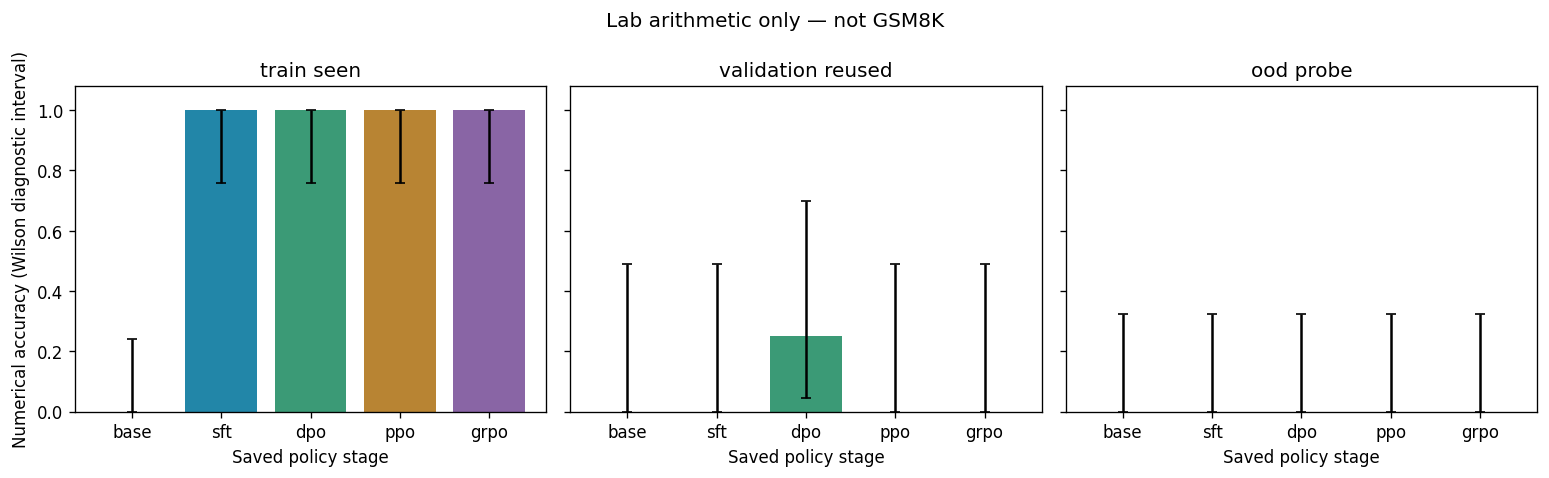

In [10]:
fig,axes = plt.subplots(1,3,figsize=(13,4),sharey=True)
for ax,split in zip(axes,("train_seen","validation_reused","ood_probe")):
    rows = [r for r in summary if r["split"] == split]
    y = np.array([r["accuracy"] for r in rows])
    errors = np.array([[r["accuracy"]-r["ci_low"] for r in rows],
                       [r["ci_high"]-r["accuracy"] for r in rows]])
    ax.bar(STAGES,y,color=["#7b8794","#2286a8","#3b9a76","#b88433","#8965a5"])
    ax.errorbar(range(len(rows)),y,yerr=errors,fmt="none",ecolor="black",capsize=3)
    ax.set_title(split.replace("_"," "))
    ax.set_ylim(0,1.08)
    ax.set_xlabel("Saved policy stage")
axes[0].set_ylabel("Numerical accuracy (Wilson diagnostic interval)")
fig.suptitle("Lab arithmetic only — not GSM8K")
fig.tight_layout()
plt.show()


### 8.1 Compare paired predictions, not unrelated percentages

The policies answered the same examples, so compare them as pairs. Define

$$d_i=z_i^{B}-z_i^{A}\in\{-1,0,1\},\qquad \widehat\Delta=\frac1N\sum_i d_i.$$

Resample example indices with replacement and carry both policies' results together. This paired bootstrap preserves example difficulty. Independently resampling model A and B discards that pairing.

The percentile interval below is descriptive on this tiny dataset. If all observed differences are zero, its interval is zero-width even though unobserved questions may behave differently. It is not proof of equivalence, and it captures neither training-seed variation nor benchmark contamination.


In [11]:
def paired_comparison(records,stage_a,stage_b,split,resamples=5000,seed=123):
    def indexed(stage):
        return {r["id"]:r for r in records if r["stage"] == stage and r["split"] == split}
    a,b = indexed(stage_a),indexed(stage_b)
    if not a or a.keys() != b.keys():
        raise ValueError("Paired evaluation requires identical, nonempty example IDs.")
    ids = sorted(a)
    diff = np.array([int(b[i]["correct"])-int(a[i]["correct"]) for i in ids])
    rng = np.random.default_rng(seed)
    estimates = diff[rng.integers(0,len(ids),size=(resamples,len(ids)))].mean(1)
    return {"a":stage_a,"b":stage_b,"split":split,"delta":float(diff.mean()),
            "bootstrap_interval":np.quantile(estimates,[0.025,0.975]).tolist(),
            "b_only_correct":int((diff==1).sum()),"a_only_correct":int((diff==-1).sum()),
            "n":len(ids)}

comparisons = [paired_comparison(records,"sft",s,split)
    for split in ("validation_reused","ood_probe") for s in ("dpo","ppo","grpo")]
for row in comparisons:
    print(row)


{'a': 'sft', 'b': 'dpo', 'split': 'validation_reused', 'delta': 0.25, 'bootstrap_interval': [0.0, 0.75], 'b_only_correct': 1, 'a_only_correct': 0, 'n': 4}
{'a': 'sft', 'b': 'ppo', 'split': 'validation_reused', 'delta': 0.0, 'bootstrap_interval': [0.0, 0.0], 'b_only_correct': 0, 'a_only_correct': 0, 'n': 4}
{'a': 'sft', 'b': 'grpo', 'split': 'validation_reused', 'delta': 0.0, 'bootstrap_interval': [0.0, 0.0], 'b_only_correct': 0, 'a_only_correct': 0, 'n': 4}
{'a': 'sft', 'b': 'dpo', 'split': 'ood_probe', 'delta': 0.0, 'bootstrap_interval': [0.0, 0.0], 'b_only_correct': 0, 'a_only_correct': 0, 'n': 8}
{'a': 'sft', 'b': 'ppo', 'split': 'ood_probe', 'delta': 0.0, 'bootstrap_interval': [0.0, 0.0], 'b_only_correct': 0, 'a_only_correct': 0, 'n': 8}
{'a': 'sft', 'b': 'grpo', 'split': 'ood_probe', 'delta': 0.0, 'bootstrap_interval': [0.0, 0.0], 'b_only_correct': 0, 'a_only_correct': 0, 'n': 8}


## 9. Why token loss and generated accuracy can disagree

Teacher forcing conditions each next-token prediction on the correct previous tokens. Free generation conditions on the model's own previous outputs. A wrong early token can send the generated sequence somewhere else entirely.

For response tokens, including EOT, let $m_t=1$ on supervised response positions and zero otherwise:

$$\mathrm{NLL}=-\frac{\sum_{i,t}m_{i,t}\log p_\theta(x_{i,t}\mid x_{i,<t})}{\sum_{i,t}m_{i,t}},\qquad \mathrm{PPL}=\exp(\mathrm{NLL}).$$

The denominator is the number of response tokens, not the number of questions. We exclude prompt targets and include the stop decision. Logits at position $t-1$ predict token $t$; an off-by-one mask silently changes the metric.

A model can increase the probability of the correct answer without making it the most likely token, so NLL improves while greedy accuracy stays constant. Conversely, a tiny probability change across an argmax boundary can flip accuracy abruptly. Perplexities across different tokenizers are not directly comparable.


In [12]:
@torch.inference_mode()
def response_nll(model,selected_examples):
    if not selected_examples:
        raise ValueError("Empty NLL dataset.")
    total_nll,total_tokens = 0.0,0
    for ex in selected_examples:
        prompt_ids = encode_ascii(ex["prompt"])
        answer_ids = [ord(c) for c in str(ex["gold"])]+[EOT]
        all_ids = prompt_ids+answer_ids
        if len(all_ids) > model.context_length:
            raise ValueError("Gold response exceeds context; do not silently truncate NLL.")
        ids = torch.tensor([all_ids],device=DEVICE)
        logits = model(ids[:,:-1])[0].float()
        losses = F.cross_entropy(logits.reshape(-1,129),ids[:,1:].reshape(-1),reduction="none")
        # Target index P-1 is the first response token, because targets start at x_1.
        selected = losses[len(prompt_ids)-1:]
        assert selected.numel() == len(answer_ids)
        total_nll += selected.sum().item()
        total_tokens += selected.numel()
    return total_nll/total_tokens,total_tokens

class UniformPolicy(nn.Module):
    context_length = 24
    def forward(self, ids):
        return torch.zeros((*ids.shape,129),device=ids.device),None
uniform_nll,uniform_count = response_nll(UniformPolicy(),examples[:1])
assert math.isclose(uniform_nll, math.log(129),abs_tol=1e-6)
assert uniform_count == 2  # One correct digit and EOT; prompt targets excluded.
print("Uniform-distribution NLL and response-token-count checks passed.")
nll_results=[]
for split in ("train_seen","validation_reused","ood_probe"):
    subset = [e for e in examples if e["split"] == split]
    for stage in STAGES:
        nll,n_tokens = response_nll(models[stage],subset)
        nll_results.append({"stage":stage,"split":split,"response_nll":nll,
                            "response_ppl":math.exp(nll),"response_tokens":n_tokens})
        print(f"{split:19} {stage:6} NLL={nll:.3f} PPL={math.exp(nll):.2f} tokens={n_tokens}")


Uniform-distribution NLL and response-token-count checks passed.
train_seen          base   NLL=7.777 PPL=2385.83 tokens=24
train_seen          sft    NLL=0.003 PPL=1.00 tokens=24
train_seen          dpo    NLL=0.079 PPL=1.08 tokens=24
train_seen          ppo    NLL=0.003 PPL=1.00 tokens=24
train_seen          grpo   NLL=0.007 PPL=1.01 tokens=24
validation_reused   base   NLL=8.043 PPL=3112.69 tokens=8
validation_reused   sft    NLL=3.418 PPL=30.52 tokens=8
validation_reused   dpo    NLL=4.365 PPL=78.66 tokens=8
validation_reused   ppo    NLL=3.268 PPL=26.26 tokens=8
validation_reused   grpo   NLL=4.000 PPL=54.61 tokens=8
ood_probe           base   NLL=7.643 PPL=2086.87 tokens=16
ood_probe           sft    NLL=4.303 PPL=73.95 tokens=16
ood_probe           dpo    NLL=4.408 PPL=82.08 tokens=16
ood_probe           ppo    NLL=4.248 PPL=69.95 tokens=16
ood_probe           grpo   NLL=4.360 PPL=78.22 tokens=16


## 10. Error analysis: inspect the evidence behind the average

Use a fixed selection rule rather than choosing flattering examples. Here we display the first three errors per stage in dataset order, and summarize machine-observable failure categories. Categories indicate symptoms, not proven causes.

| Observation | Next diagnostic |
|---|---|
| No budget | Inspect prompt token length versus model context |
| No parsed number | Inspect raw completion and chat-template compatibility |
| Wrong numeric answer | Check gold, parser, then the actual generated text |
| Correct number but malformed response | Separate formatting from arithmetic |
| Reaches length cap | Repeat a preregistered larger-budget experiment, labelled separately |
| Good train score, poor validation | Inspect memorization and data coverage; do not tune on final test |

After SFT, a stronger model may adopt the expected answer structure. That is behavioral evidence, but the repo's statement is not a promise that every small run will improve. Our tiny model was trained on compact digit responses, not `<think>` tags. Read what this run actually generated.


In [13]:
def failure_category(row):
    if row["finish_reason"] == "no_budget": return "no_budget"
    if row["parsed"] is None: return "unparseable"
    if not row["correct"]: return "wrong_number"
    if not row["strict_format"]: return "correct_number_wrong_format"
    return "correct_digit"

for stage in STAGES:
    rows = [r for r in records if r["stage"] == stage]
    counts = defaultdict(int)
    for row in rows: counts[failure_category(row)] += 1
    print("\n",stage,dict(counts))
    errors = [r for r in rows if r["split"] != "train_seen" and not r["strict_correct"]]
    for row in errors[:3]:
        print(row["id"],"gold=",row["gold"],"response=",repr(row["response"]),
              "parsed=",row["parsed"],"stop=",row["finish_reason"])



 base {'unparseable': 24}
validation_reused:0+1 gold= 1 response= 'nd a to ' parsed= None stop= length
validation_reused:1+3 gold= 4 response= 'nd a to ' parsed= None stop= length
validation_reused:2+2 gold= 4 response= 'nd a the' parsed= None stop= length

 sft {'correct_digit': 12, 'wrong_number': 12}
validation_reused:0+1 gold= 1 response= '2' parsed= 2.0 stop= eot
validation_reused:1+3 gold= 4 response= '3' parsed= 3.0 stop= eot
validation_reused:2+2 gold= 4 response= '5' parsed= 5.0 stop= eot

 dpo {'correct_digit': 13, 'wrong_number': 10, 'unparseable': 1}
validation_reused:1+3 gold= 4 response= '3' parsed= 3.0 stop= eot
validation_reused:2+2 gold= 4 response= '5' parsed= 5.0 stop= eot
validation_reused:3+0 gold= 3 response= '1' parsed= 1.0 stop= eot

 ppo {'correct_digit': 12, 'wrong_number': 12}
validation_reused:0+1 gold= 1 response= '2' parsed= 2.0 stop= eot
validation_reused:1+3 gold= 4 response= '3' parsed= 3.0 stop= eot
validation_reused:2+2 gold= 4 response= '5' parsed= 

## 11. Save an auditable evaluation package

A table alone cannot explain how a score was produced. Save the frozen inputs, raw predictions, summary metrics, and a manifest containing checkpoint hashes and the evaluation contract. Use a new output directory per run to avoid duplicate appended rows.

Unlike the repository's minimal `--append` output (label, accuracy, correct, n), this lab preserves per-example data. You can rescore without rerunning generation; any changed scoring protocol must get a new version. Do not overwrite old results and silently relabel them.


In [14]:
manifest = {
    "track":"lab_arithmetic", "dataset_sha256":DATASET_HASH,
    "checkpoints":{s:{"path":str(p),"sha256":sha256_file(p)} for s,p in CHECKPOINTS.items()},
    "tokenizer":EXPECTED_TOKENIZER,"prompt_template":"U:{a}+{b}\nA:",
    "decoding":{"mode":"argmax","max_new_tokens":MAX_NEW_TOKENS,"micro_batch":MICRO_BATCH,
                "eot":EOT,"context_length":base_cfg["context_length"],"rollover":False},
    "scorer":SCORER_VERSION,"seed":42,"torch":str(torch.__version__),"device":DEVICE,
    "denominator_policy":"all frozen examples; empty completion is incorrect",
    "timing_seconds_exploratory":timings,
    "limitations":["tiny nonrepresentative arithmetic dataset","validation reused from Lab 05",
                    "single training run","constrained PPO/GRPO teaching setup","not GSM8K"]}
(RUN_DIR/"manifest.json").write_text(json.dumps(manifest,indent=2))
(RUN_DIR/"dataset.json").write_text(json.dumps(examples,indent=2))
(RUN_DIR/"predictions.jsonl").write_text("".join(json.dumps(r)+"\n" for r in records))
(RUN_DIR/"summary.json").write_text(json.dumps(summary,indent=2))
(RUN_DIR/"paired_comparisons.json").write_text(json.dumps(comparisons,indent=2))
(RUN_DIR/"response_nll.json").write_text(json.dumps(nll_results,indent=2))
with (RUN_DIR/"summary.csv").open("w",newline="") as f:
    writer = csv.DictWriter(f,fieldnames=list(summary[0]))
    writer.writeheader();writer.writerows(summary)
reloaded = [json.loads(line) for line in (RUN_DIR/"predictions.jsonl").read_text().splitlines()]
assert reloaded == records
for row in summary:
    relevant = [r for r in reloaded if r["stage"] == row["stage"] and r["split"] == row["split"]]
    assert len(relevant) == row["n"]
    assert sum(r["correct"] for r in relevant) == row["correct"]
print("Saved and checked:",RUN_DIR)
print("Files:",[p.name for p in sorted(RUN_DIR.iterdir())])


Saved and checked: /workspace/scratch/d20f4a09d498/lab06_runs/evaluation_uga55ouu
Files: ['dataset.json', 'manifest.json', 'paired_comparisons.json', 'predictions.jsonl', 'response_nll.json', 'summary.csv', 'summary.json']


## 12. Track B — the actual repository GSM8K evaluation

### 12.1 Match the repository, not the teaching tokenizer

Repository evaluation uses `openai/gsm8k`, configuration `main`, normally split `test`. The default CLI evaluates the **first 200** rows, not a random sample. `load_gsm8k_eval` selects a prefix when `limit` is truthy; `limit=0` means the full split in the inspected implementation. Use a positive explicit limit for smoke tests.

The repository uses `r50k_base`, EOT ID **50256**, and textual role headers encoded as ordinary tokens. The user message ends in EOT, followed by an assistant generation header. Its model vocabulary may be padded to 50304; its decoder ignores IDs outside the valid text-token range. None of those IDs are interchangeable with the ASCII Lab tokenizer.

`load_model_from_ckpt` reconstructs the repository architecture from checkpoint metadata and normalizes supported wrapper prefixes. Use that loader for repository checkpoints rather than forcing them into the Lab class. Keep all stages from a compatible training run. `gsm8k_accuracy` uses the chat prompt even for the base stage.

The shared evaluator groups identical token lengths (default microbatch 32), limits generation to the remaining context, stops at EOT and restores input order. Its CLI defaults are `--split test`, `--limit 200`, `--max_new_tokens 300`, `--samples 3`, and an available CUDA device or CPU.

### 12.2 Canonical command-line reproduction

In a terminal, clone the repository if needed, follow its installation instructions, and place your trained stage checkpoints under `models/`. Use a **new log path** for each experiment: append mode does not deduplicate labels.

```bash
# From the repository root, after installing its dependencies:
for s in base_pretrained sft dpo ppo grpo; do
  python scripts/eval_post_training.py \
    --ckpt models/$s.pt --label $s \
    --split test --limit 200 --max_new_tokens 300 --samples 3 \
    --append logs/lab06_gsm8k_run01.jsonl
done
python scripts/eval_post_training.py --table logs/lab06_gsm8k_run01.jsonl
```

Start with `--limit 4` to check loading and generation. That is an integration smoke test, not a publishable benchmark. An absent checkpoint or dataset is a setup failure, not a score of zero. Do not substitute fresh random weights.

### 12.3 Notebook runner with per-example exports

The following optional path calls the actual repository functions. It records a Git commit, dataset fingerprint, question IDs, file hashes, prompt lengths, responses, and numerical/format metrics. It also checks agreement with `gsm8k_accuracy` on the first four examples for every stage. It does not train or download model weights.

Set `REPO_ROOT`, verify the checkpoints, and set `RUN_GSM8K=True` only in a kernel with that repository's dependencies installed (including `datasets` and `tiktoken`). Restart the kernel before switching between different repository checkouts: Python caches imported modules. Dataset loading may download GSM8K. Use a suitable GPU if the checkpoints are too large for CPU memory.


In [15]:
RUN_GSM8K = False
REPO_ROOT = Path("train-llm-from-scratch").resolve()
REPO_MODELS = {s:REPO_ROOT/"models"/f"{s}.pt"
               for s in ("base_pretrained","sft","dpo","ppo","grpo")}
GSM8K_LIMIT = 200
GSM8K_SPLIT = "test"
GSM8K_MAX_NEW_TOKENS = 300
GSM8K_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GSM8K_STATUS = "not run"

if not RUN_GSM8K:
    print("GSM8K NOT RUN: set REPO_ROOT, supply trained repository checkpoints, then enable RUN_GSM8K.")
else:
    if GSM8K_LIMIT <= 0:
        raise ValueError("Use a positive explicit limit in this runner.")
    for path in REPO_MODELS.values():
        if not path.is_file(): raise FileNotFoundError(path)
    if not (REPO_ROOT/"src/post_training/evaluation.py").is_file():
        raise FileNotFoundError("REPO_ROOT must point to the actual repository checkout.")
    sys.path.insert(0,str(REPO_ROOT))
    from datasets import load_dataset
    import src.post_training.evaluation as repo_eval
    from src.post_training.inference import load_model_from_ckpt
    from src.post_training.chat_template import encode_prompt as repo_encode_prompt
    from src.post_training.rewards import gsm8k_gold_answer as repo_gold, is_correct as repo_is_correct
    from src.post_training.rewards.parsing import has_well_formed_answer as repo_format
    assert Path(repo_eval.__file__).resolve().is_relative_to(REPO_ROOT), "Restart kernel: wrong imported checkout"
    commit = subprocess.check_output(["git","rev-parse","HEAD"],cwd=REPO_ROOT,text=True).strip()
    dirty = subprocess.check_output(["git","status","--porcelain"],cwd=REPO_ROOT,text=True).strip()
    if dirty:
        raise RuntimeError("Use a clean recorded checkout for reproducibility; commit local changes first.")
    dataset = load_dataset("openai/gsm8k","main",split=GSM8K_SPLIT)
    selected = dataset.select(range(min(GSM8K_LIMIT,len(dataset))))
    qa = [(r["question"],r["answer"]) for r in selected]
    if not qa: raise ValueError("Empty benchmark dataset")
    assert qa == repo_eval.load_gsm8k_eval(GSM8K_SPLIT,GSM8K_LIMIT)
    golds = [repo_gold(a) for _,a in qa]
    if any(g is None or not math.isfinite(g) for g in golds):
        raise ValueError("Invalid gold answer; inspect dataset before evaluating")
    prompts = [repo_encode_prompt([{"role":"user","content":q}]) for q,_ in qa]
    output_dir = RUN_DIR/"gsm8k"; output_dir.mkdir(exist_ok=False)
    gsm_rows,gsm_summary = [],[]
    for stage,path in REPO_MODELS.items():
        torch.manual_seed(42)
        model = load_model_from_ckpt(str(path),device=GSM8K_DEVICE)
        if GSM8K_DEVICE.startswith("cuda"): torch.cuda.synchronize()
        started = time.perf_counter()
        responses = repo_eval.batched_generate(model,prompts,GSM8K_MAX_NEW_TOKENS,
                                               device=GSM8K_DEVICE,greedy=True)
        if GSM8K_DEVICE.startswith("cuda"): torch.cuda.synchronize()
        elapsed = time.perf_counter()-started
        assert len(responses) == len(qa)
        cap = getattr(getattr(model,"transformer",model),"context_length",1024)
        rows = []
        for i,((q,a),gold,response,prompt_ids) in enumerate(zip(qa,golds,responses,prompts)):
            rows.append({"stage":stage,"id":f"{GSM8K_SPLIT}:{i}","question":q,
                "gold_field":a,"gold":gold,"response":response,
                "correct":bool(repo_is_correct(response,gold)),
                "answer_block":bool(repo_format(response)),
                "prompt_tokens":len(prompt_ids),
                "available_budget":max(0,min(GSM8K_MAX_NEW_TOKENS,cap-len(prompt_ids)))})
        # Integration check against the repository's headline aggregation.
        torch.manual_seed(42)
        check = repo_eval.gsm8k_accuracy(model,qa[:4],max_new_tokens=GSM8K_MAX_NEW_TOKENS,
                                        device=GSM8K_DEVICE,greedy=True,return_samples=4)
        assert check["correct"] == sum(r["correct"] for r in rows[:4])
        k = sum(r["correct"] for r in rows); n = len(rows)
        gsm_summary.append({"label":stage,"accuracy":k/n,"correct":k,"n":n,
            "wilson_interval":wilson_interval(k,n),
            "answer_block_rate":sum(r["answer_block"] for r in rows)/n,
            "no_budget_rate":sum(r["available_budget"]==0 for r in rows)/n,
            "elapsed_seconds":elapsed,"checkpoint_sha256":sha256_file(path)})
        gsm_rows.extend(rows)
        # Save each completed stage immediately, retaining partial progress if a later stage fails.
        (output_dir/f"{stage}.predictions.jsonl").write_text("".join(json.dumps(r)+"\n" for r in rows))
        print(gsm_summary[-1])
        del model
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    (output_dir/"summary.json").write_text(json.dumps(gsm_summary,indent=2))
    (output_dir/"manifest.json").write_text(json.dumps({
        "repo_commit":commit,"dataset":"openai/gsm8k","config":"main","split":GSM8K_SPLIT,
        "dataset_fingerprint":selected._fingerprint,"dataset_sha256":canonical_hash(qa),
        "selection":"prefix","n":len(qa),"max_new_tokens":GSM8K_MAX_NEW_TOKENS,
        "greedy":True,"seed":42,"device":GSM8K_DEVICE,"torch":str(torch.__version__),
        "checkpoint_paths":{s:str(p) for s,p in REPO_MODELS.items()},
        "status":"completed"},indent=2))
    GSM8K_STATUS = "completed"
    print("Actual GSM8K evaluation completed:",output_dir)


GSM8K NOT RUN: set REPO_ROOT, supply trained repository checkpoints, then enable RUN_GSM8K.


### 12.4 What the optional runner does and does not measure

Its scores come from the actual repository functions, not our ASCII implementation. It records answer-block rate and zero-budget cases, but the repository `batched_generate` returns only decoded strings. It therefore cannot reliably distinguish an EOT stop from reaching the length cap. Do not infer that reason from response length alone; instrument the rollout return values if you need exact finish diagnostics.

If the four-example parity check fails, first inspect ties, stochastic filtering, device nondeterminism, and upstream API changes. Do not suppress the assertion to obtain a table.

Run a final fixed benchmark once the model and protocol are selected. Repeatedly tuning on the GSM8K test prefix turns it into a development set. Use training-split development data for protocol tuning, inspect contamination risks, and reserve an independent final evaluation. A high GSM8K score does not establish broad helpfulness, safety, multilingual ability, or reasoning faithfulness.


## 13. Independent exercises — implement, measure, explain

Complete these in new cells, leaving the reference run intact. The experiments change one factor at a time and produce new output directories or distinct protocol labels.

### Exercise A — Adversarial scorer audit (15 points)
Create at least 12 cases covering commas, negatives, multiple tags, empty tags, extra numbers, fractions, scientific notation, missing gold, and prompt leakage. For each, write the expected result **before** executing. Add a strict alternative parser and quantify disagreement on saved predictions. Keep the original repository-compatible score visible.

**Acceptance:** tests check explicit expected values; no gold answer is included in generated input; malformed examples are not silently removed. Explain one false positive caused by tolerant fallback.

### Exercise B — Variable-length generation (20 points)
Add prompts of at least three lengths, an immediate-EOT case, a row that reaches its budget, and a zero-budget prompt. Compare microbatch sizes 1, 2 and 8. Use fixtures to verify ordering; then repeat with a real checkpoint.

**Acceptance:** per-example outputs agree for unique argmax logits; every input retains exactly one output; context capacity is never exceeded; termination reasons are correct. Do not pad before generation without adding and validating a proper attention mask.

### Exercise C — Budget sensitivity (20 points)
Evaluate every stage with budgets 1, 2, 4 and 8 on the same frozen data. Plot numerical accuracy, strict accuracy and EOT rate against budget. Keep all four experiments visible.

**Acceptance:** manifests differ only in the intended budget parameter; denominator stays constant. Explain why one token can yield a correct digit but no EOT, and why more tokens can hurt a last-number parser.

### Exercise D — Paired comparison (15 points)
Construct two policies with equal marginal accuracy but different solved questions. Implement counts for both-correct, A-only, B-only and neither. Check that the four counts sum to N and that the accuracy difference is `(B_only - A_only)/N`.

**Acceptance:** pairing uses stable IDs; missing or duplicate IDs fail loudly. Explain why identical accuracy does not imply identical behavior.

### Exercise E — Actual repository evaluation (20 points)
Run the repository on four GSM8K questions first, then a frozen 200-question prefix, then the full split if resources permit. Preserve checkpoint hashes, dataset identity, raw predictions, and the exact command or runner settings. Compare Base/SFT/DPO/PPO/GRPO; inspect the first five errors under a fixed ordering rule.

**Acceptance:** real trained repository checkpoints and the repository tokenizer are used; tiny arithmetic results never appear under a GSM8K label. If resources are unavailable, submit the integration plan and mark this exercise **not executed**; do not fabricate scores.

### Exercise F — Evaluation memo (10 points)
Write 300–500 words answering: what improved, on which inputs, under which protocol, with what uncertainty, and what remains unknown? Separate observations from causal explanations. State the next experiment you would run and what result would change your conclusion.

**Acceptance:** no algorithm-superiority claim from one training run; validation reuse and training constraints are disclosed; each quantitative claim traces to a saved result.


## 14. Hints, diagnostic questions, and completion criteria

**Exercise A hint:** `<answer></answer>` passes the repository's block-count check but may yield no number; `1/2` inside a tag is parsed as 1. A robust new parser might reject fractions, but changing this behavior creates a new metric.

**Exercise B hint:** group by token length, retain original indices, and test each output's identity. A correctly shaped output tensor can still have permuted answers.

**Exercise C hint:** score generated text after removing EOT. With a budget of one, the digit can be correct while the stop decision remains unobserved. Accuracy and termination compliance should be separate columns.

**Exercise D answer sketch:** A solves examples {1,2}, B solves {2,3}, out of four. Both score 50%; A-only=1, B-only=1, both=1, neither=1. The mean paired difference is zero, but behavior differs on half the examples.

**Exercise E hint:** begin with the CLI smoke run to verify dependencies and checkpoint format. A larger-context repository model is necessary for realistic GSM8K prompts; do not crop questions until they fit a 24-character teaching model and call that a faithful benchmark.

**Exercise F hint:** “DPO scored higher than SFT on this frozen set” is an observation. “DPO is a better algorithm” requires controlled training budgets, multiple runs, broader tasks, and uncertainty analysis beyond this lab.

### Troubleshooting

| Failure | Likely cause and action |
|---|---|
| Missing checkpoint | Run the earlier lab or set the explicit path; do not initialize replacement weights |
| Strict state-dict mismatch | Wrong architecture or stage; inspect metadata and use the correct loader |
| Tokenizer mismatch | Repository BPE checkpoint passed to the ASCII practical, or vice versa |
| All outputs empty | Prompt length exhausted context, or immediate EOT; inspect token budgets and IDs |
| High reward but low accuracy | Format shaping, learned-reward errors, or a metric mismatch |
| High training accuracy, poor probes | Memorization or distribution shift; inspect data before choosing an explanation |
| Duplicate stage rows in CLI table | Reused append log; create a fresh run log rather than cherry-picking entries |
| CUDA out of memory | Reduce microbatch in the API runner or use a smaller trained model; record the change |
| Wrong repository module imported | Restart the kernel and set REPO_ROOT before importing `src` |

### Definition of done

- Track A runs top to bottom using actual Lab 03–05 checkpoint files.
- Scorer and generation contract checks pass.
- Five policies are evaluated on identical frozen inputs without retraining.
- Training, reused validation, and OOD probes remain distinct.
- Raw outputs, counts, confidence diagnostics, paired comparisons, NLL and manifests are saved.
- Track B is either actually completed or clearly labelled not executed.
- The final memo states both what the evidence supports and what it cannot establish.

**What comes next:** Step 7 uses the same checkpoint, tokenizer, prompt and generation machinery for chat. Interactive examples help diagnose behavior; they do not replace the fixed evaluation protocol you built here.


In [16]:
print("LAB 06 EXECUTION RECEIPT")
print("Track A: completed with",len(STAGES),"real policies and",len(examples),"examples per policy")
print("Scorer cases, bucket contracts, real-model repeat, and saved-count checks: passed")
print("Track B / actual GSM8K:",GSM8K_STATUS)
print("Evidence directory:",RUN_DIR)
print("Interpretation: these CPU arithmetic results do not establish GSM8K or general assistant capability.")


LAB 06 EXECUTION RECEIPT
Track A: completed with 5 real policies and 24 examples per policy
Scorer cases, bucket contracts, real-model repeat, and saved-count checks: passed
Track B / actual GSM8K: not run
Evidence directory: /workspace/scratch/d20f4a09d498/lab06_runs/evaluation_uga55ouu
Interpretation: these CPU arithmetic results do not establish GSM8K or general assistant capability.


## 15. Reading the included reference run

The included execution uses the saved Lab 03 base and Lab 05 run `run_46tulole`. On the 12 seen training pairs, all four post-trained policies answer every question correctly. On the four reused validation pairs, DPO answers one correctly; the other stages answer none. No policy answers any of the eight OOD probes correctly.

This supports a narrow conclusion: these small policies largely memorized the training pairs under the compact prompt format. DPO's one additional validation success is worth inspecting, but four examples cannot establish an algorithmic advantage. Its validation response NLL is worse than SFT's even though its greedy accuracy is higher—an observed example of the distinction in Section 9.

The base produces nonnumeric text; SFT usually produces a digit and EOT. That is a clear format change without corresponding broad arithmetic generalization. The lesson is not to hide low scores: a useful evaluator reveals where the model fails.

If you rerun with different checkpoint files, replace this interpretation with conclusions drawn from your own outputs. The actual GSM8K track was not executed for this reference run.
